# V55 — Una sola red neuronal (en cadena) contra el minimax, con tope de 20 láminas por material (6 materiales)

**Criterio.** Una sola metodología: la red en cadena de la Figura 5 da las láminas enteras y se compara siempre contra el minimax.
Ningún material puede tener más de **20 láminas** (Z_MAX = 20), para no complicar la fabricación; el tope se aplica al minimax
(etiquetas de entrenamiento y referencia) y a la red (21 clases por cabeza: 0 a 20).

- Celdas 0–8: las de V40 (curvas, bases, 50 000 curvas sintéticas, partición); las etiquetas enteras se recalculan con el tope (Celda 7).
- Celda 9: el minimax (MILP, HiGHS) con 0 ≤ z ≤ 20, la referencia.
- Celda 10: herramientas de comparación y búsqueda de ±1 lámina (dentro de 0 a 20).
- Celdas 11–12: la red en cadena: tronco común y una cabeza por material que conoce las láminas ya elegidas.
- Celdas 13–15: acierto en las curvas de prueba, tabla final (41 sujetos y 2000 curvas) y figura.

**Archivos que necesita en la carpeta:** `tabla2_masson_NT.csv`, `tabla4_masson_HT.csv`, `masson2011_curvas_medias.csv`, `bases_v40_6.csv`.
Las etiquetas `etiquetas_enteras_v55_6.npz` (≈ 1 h de cálculo) y los pesos `modelo_rn_curva_j_v55_6_cadena.weights.h5`
se cargan si están; si no, se calculan.


In [1]:
# CELDA 0: CONFIGURACIÓN (ejecutar siempre primero)
import os
import numpy as np

N_BASES = 6                      # ← número de bases (materiales): 4, 5 o 6. Cada número de bases tiene su propia red
VERSION = f"v56_{N_BASES}"
SEED = 42
DIR_MASSON = "."                 # tablas de Masson en la misma carpeta que el notebook
ENTRENAR = "auto"                # "auto": carga la red si sus archivos están en la carpeta y, si no, la entrena;
                                 # True: entrena siempre; False: carga siempre (error si faltan los archivos)
# ENSAYOS DE LOS MATERIALES: un solo CSV con la columna lambda (estiramiento circunferencial del injerto, el mismo λθ de las curvas,
#   con el montaje y el rizado de las fibras ya incluidos) y una columna material_j por cada material ensayado (tensión de Cauchy
#   [MPa]). Los materiales sin columna (o con la columna vacía) siguen con su base ideal (recta truncada: fibra como hilo).
#   Con ensayos, la red se REENTRENA (Celda 11, ≈ 40–60 min). Formato: ver plantilla_ensayos_v40_N.csv.
ARCHIVO_ENSAYOS = f"ensayos_v40_{N_BASES}.csv"   # si el archivo no está en la carpeta: bases ideales
GUARDAR_PLANTILLA_ENSAYO = True  # True: la Celda 3 escribe plantilla_ensayos_v40_N.csv (las bases ideales en el formato del ensayo)
ENSAYOS = []                     # materiales ensayados (se detectan solos)
if os.path.exists(ARCHIVO_ENSAYOS):
    import pandas as pd
    _e = pd.read_csv(ARCHIVO_ENSAYOS)
    ENSAYOS = [j for j in range(1, N_BASES + 1) if f"material_{j}" in _e and _e[f"material_{j}"].notna().sum() >= 2]
# Red: con bases ideales se usa la red de V35 (mismas bases); con ensayos, una red propia que se entrena la primera vez.
# V40 (idea del director): la red se entrena con las láminas ENTERAS del redondeo minimax (MILP, HiGHS) de cada curva, no con las
#   láminas reales del MCO. La red de V39/V35 (etiquetas MCO) se usa solo para comparar (Celda 27).
MODELO_RED = f"{VERSION}_enteras" if not ENSAYOS else f"{VERSION}_enteras_ensayos_" + "_".join(map(str, ENSAYOS))
MODELO_COMPARACION = f"v35_{N_BASES}"   # red entrenada con láminas reales del MCO (V35 = V39), para la Celda 27
ARCHIVO_ETIQUETAS_ENTERAS = f"etiquetas_enteras_v56_{N_BASES}.npz"   # las 50 000 curvas generadas (la Celda 8 deja las de la banda)
Z_MAX = 20                                # V55: tope de láminas por material (fabricación), en el minimax y en la red   # minimax de las 50 000 curvas (lento: se guarda y se reutiliza)
MODELO_RED = f"{VERSION}_cadena"          # una sola red: la red en cadena, entrenada dentro de y1–y2
if ENTRENAR == "auto":
    ENTRENAR = not os.path.exists(f"modelo_rn_curva_j_{MODELO_RED}.weights.h5")

# V35: las curvas son TENSIONES σθθ(λθ) en r_m (ley de Masson), no presiones. Cada base = UNA lámina de un material:
#   A_j(λ) = S_j·max(0, λ − k_j)   (recta truncada), con S_j = PEND_MAX_j / C_LAM_j.
#   Nudos k_j y pendientes S_j se ajustan desde cero a las curvas de σ (Celda 3).
ARCHIVO_BASES = f"bases_v40_{N_BASES}.csv"   # nudos y pendientes de las bases: la Celda 3 los lee de acá; si no existe, busca los
                                             # nudos (≈ 25 min) y lo escribe (columnas material, nudo, pendiente_lamina_kPa)
OPTIMIZAR_NUDOS = False          # True: vuelve a buscar los nudos (y sobrescribe ARCHIVO_BASES) aunque el archivo exista
NUDOS_FORZADOS = None            # opcional: una lista de N_BASES nudos para imponerlos a mano (ignora el archivo)
UMBRAL_COND = 30.0               # cota de cond(A) (columnas normalizadas) que deben cumplir los nudos
PESO_NEG = 10.0                  # peso de la penalización por láminas negativas del MCO libre al elegir los nudos (evaluada en todo el espacio)
SIGNO_ESTRICTO = True            # True: la Celda 3 exige 0 curvas del espacio de trabajo con láminas < −TOL_NEG
SEP_MIN_NUDOS = 0.008            # separación mínima entre nudos
MARGEN_NUDO_FINAL = 0.012        # el último nudo queda ≥ 0,012 antes de X_MAX: si no, su material actúa en muy pocos puntos y la red no lo distingue
TOL_NEG = 0.01                   # lámina negativa tolerada (en láminas de la red, de 10): 0,1 % del máximo
C_LAM = 20                       # máximo de láminas por material (configuración adoptada: 20) (solo para las Celdas 3 a 22): un número para todos o una lista de N_BASES valores; no requiere reentrenar
C_LAM_RED = 10.0                 # láminas con que se entrena la red (no cambiar)

ERROR_MAX_PCT = 3.0              # criterio: error punto a punto ≤ 3 % del rango de la curva
SUJETO_Y1, SUJETO_Y2 = "NT16", "HT09"                            # sujetos de partida de las curvas límite
# y1: ley de Masson con la geometría y las fibras de NT16 y estos 5 parámetros (dentro del rango de los 41 sujetos),
#     elegidos para que y1(X_MIN) = mín. de los 41 sujetos en X_MIN (HT10, 4,71 kPa) y y1 ≤ los 41 sujetos en todo el dominio
PARAM_Y1 = {"c_kPa": 43.6135, "c1_kPa": 5.0302, "c1circ_kPa": 5.1034, "c2circ": 11.8183, "Tm_kPa": 22.3336}
LAMBDA_Y2, Y2_MAX = 1.10, 300.0  # y2 = HT09 hasta LAMBDA_Y2 y luego llega a Y2_MAX [kPa] en X_MAX (≥ los 41 sujetos)
X_MIN, X_MAX, N_PTS = 1.02, 1.16, 999
X = np.linspace(X_MIN, X_MAX, N_PTS)
FRAC_SUJETOS_TEST = 0.25
X_INICIO_CONVEXIDAD, TOL_FORMA_REL = 1.05, 0.01                  # control de forma J
TOL_CLASE_NRMSE, N_NUDOS_CLASE, NUDO_MIN_CLASE = 2.0, 40, 0.85   # control de clase a la entrada
ETQ_X, ETQ_Y = r"$\lambda_\theta$ (en $r_m$)", r"$\sigma_{\theta\theta}$ en $r_m$ [kPa]"
ETQ_YN = r"$(\sigma - \sigma_{mín})/\Delta\sigma$"     # forma adimensional: 0 en λ = X_MIN, 1 en λ = X_MAX

_v = MODELO_RED
ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL = (f"modelo_rn_curva_j_{_v}.weights.h5", f"scalers_curva_j_{_v}.pkl",
                                                      f"historial_entrenamiento_{_v}.csv")
print(f"✅ {VERSION} | curvas σθθ(λθ) en r_m | λθ ∈ [{X_MIN}, {X_MAX}] | {N_BASES} bases "
      f"({'ideales' if not ENSAYOS else 'ensayos de los materiales ' + str(ENSAYOS)}) | "
      f"red: {'se entrena → ' if ENTRENAR else 'se carga de '}{ARCHIVO_MODELO}")

✅ v56_6 | curvas σθθ(λθ) en r_m | λθ ∈ [1.02, 1.16] | 6 bases (ideales) | red: se entrena → modelo_rn_curva_j_v56_6_cadena.weights.h5


In [2]:
# CELDA 1: MODELO DE MASSON ET AL. (2011) Y CURVAS σθθ(λθ) DE LOS 41 SUJETOS
# σθθ: tensión circunferencial de Cauchy en r_m (borde media–adventicia), como en las Figs. 5a y 7a de Masson.
# Sale directo de la ley de Masson con los parámetros de las Tablas 2 y 4: no hace falta suponer el espesor de la pared.
import os
import numpy as np
import pandas as pd

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def sigma_masson(lt, p, restar_Pa=True):
    """σθθ(λθ) [kPa] en r_m: elastina neo-Hookeana + 4 familias de colágeno + tono activo."""
    lt = np.asarray(lt, float)
    lz, al = p["lambda_ax"], np.deg2rad(p["alpha_deg"])
    lam_d = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    suma = np.zeros_like(lt)
    for lam_k, c1, c2, ang in [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0), (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),
                               (lam_d, p["c1_kPa"], p["c2"], al), (lam_d, p["c1_kPa"], p["c2"], -al)]:
        E = lam_k ** 2 - 1.0
        suma = suma + c1 * E * np.exp(c2 * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    s = -p["c_kPa"] * (1.0 / (lt * lz)) ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo
    return s - p["a_kPa"] * np.exp(p["b"]) if restar_Pa else s


def curva_objetivo(lt_m, p):
    """σθθ(λθ) en r_m [kPa] (ley de Masson, con la presión perivascular P_a restada como en el paper)."""
    return sigma_masson(np.asarray(lt_m, float), p, restar_Pa=True)


def diagnostico_forma(y, x=X):
    """(monótona, convexa desde X_INICIO_CONVEXIDAD), con tolerancia relativa a la pendiente máxima."""
    p = np.diff(y) / np.diff(x)
    tol = TOL_FORMA_REL * max(float(np.abs(p).max()), 1e-9)
    return bool(p.min() >= -tol), bool(np.diff(p)[x[1:-1] >= X_INICIO_CONVEXIDAD].min() >= -tol)


POB = pd.concat([pd.read_csv(f"{DIR_MASSON}/{f}").assign(grupo=g) for f, g in
                 [("tabla2_masson_NT.csv", "NT"), ("tabla4_masson_HT.csv", "HT")]], ignore_index=True)
POB["id"] = POB["grupo"] + POB["subject"].map("{:02d}".format)
POB_Y = np.array([curva_objetivo(X, r) for _, r in POB.iterrows()])

# Sujetos reservados para test (estratificado por grupo): no entran al generador
_rng = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    i_g = POB.index[POB["grupo"] == g].to_numpy()
    POB.loc[_rng.choice(i_g, size=int(round(FRAC_SUJETOS_TEST * len(i_g))), replace=False), "test"] = True
MASK_TEST = POB["test"].to_numpy()
MASK_TRAIN = ~MASK_TEST

# Curvas límite: y1 = ley de Masson (geometría de NT16 con PARAM_Y1), por debajo de los 41 sujetos y con y1(X_MIN) = mín. medido;
# y2 = HT09 + a·(exp(b·E²) − 1), E = (λ/LAMBDA_Y2)² − 1 > 0, con b = c2circ de HT09 y a tal que y2(X_MAX) = Y2_MAX
_p1 = POB.loc[POB["id"] == SUJETO_Y1].iloc[0].copy()
for _k, _v in PARAM_Y1.items():
    _p1[_k] = _v
Y1 = curva_objetivo(X, _p1)
_y2 = POB_Y[(POB["id"] == SUJETO_Y2).to_numpy()][0]
_g = np.exp(float(POB.loc[POB["id"] == SUJETO_Y2, "c2circ"].iloc[0]) * np.maximum(0.0, (X / LAMBDA_Y2) ** 2 - 1.0) ** 2) - 1.0
Y2 = _y2 + (Y2_MAX - _y2[-1]) / _g[-1] * _g
_i0 = int(POB_Y[:, 0].argmin())
assert abs(Y1[0] - POB_Y[_i0, 0]) < 1e-3, "y1(X_MIN) debe ser la menor tensión medida en X_MIN"
assert np.all(Y1 <= POB_Y.min(axis=0) + 1e-6), "y1 debe quedar por debajo de los 41 sujetos"
assert all(diagnostico_forma(Y1)), "y1 debe tener forma J"
ETQ_BANDA = f"Curvas límite y1 (Masson, y1({X_MIN}) = {Y1[0]:.2f} kPa = {POB.id[_i0]}) – y2 ({SUJETO_Y2} → {Y2_MAX:g} kPa)"
print(f"y1: ley de Masson, y1({X_MIN}) = {Y1[0]:.3f} kPa (= {POB.id[_i0]}), y1({X_MAX}) = {Y1[-1]:.2f} kPa; "
      f"distancia mínima a los 41 sujetos fuera de X_MIN: {(POB_Y.min(axis=0) - Y1)[1:].min():.4f} kPa")


def dentro_espacio(Y, tol=1e-9):
    Y = np.atleast_2d(Y)
    return np.all((Y >= Y1 - tol) & (Y <= Y2 + tol), axis=1)


def banda(ax, x=X):
    ax.fill_between(x, np.interp(x, X, Y1), np.interp(x, X, Y2), color="#e5e7eb", alpha=0.6, lw=0, label=ETQ_BANDA)


GRUPOS_MEDIAS = {"Mean Young": (POB["grupo"] == "NT") & (POB["age"] <= 42), "Mean Old": (POB["grupo"] == "NT") & (POB["age"] >= 53),
                 "Mean NT": (POB["grupo"] == "NT") & (POB["age"] >= 39), "Mean HT": POB["grupo"] == "HT"}
MEDIAS = {k: POB_Y[m.to_numpy()].mean(axis=0) for k, m in GRUPOS_MEDIAS.items()}

_dent = dentro_espacio(POB_Y)
print(f"✅ {len(POB)} sujetos ({(POB.grupo == 'NT').sum()} NT, {(POB.grupo == 'HT').sum()} HT) | test: {', '.join(POB.id[MASK_TEST])}")
print(f"   σθθ en λ = {X_MIN}: [{POB_Y[:, 0].min():.1f}, {POB_Y[:, 0].max():.1f}] kPa | en λ = {X_MAX}: "
      f"[{POB_Y[:, -1].min():.1f}, {POB_Y[:, -1].max():.1f}] kPa | forma J (monótona y convexa): "
      f"{np.mean([all(diagnostico_forma(y)) for y in POB_Y]):.0%}")
print(f"   Dentro de y1–y2 en todo el dominio: {_dent.sum()}/{len(POB)} | fuera: {', '.join(POB.id[~_dent])}")

# Validación contra las medias de σθθ digitalizadas del paper (Figs. 5a y 7a)
if os.path.exists(f"{DIR_MASSON}/masson2011_curvas_medias.csv"):
    dig = pd.read_csv(f"{DIR_MASSON}/masson2011_curvas_medias.csv")
    for k, m in GRUPOS_MEDIAS.items():
        d = dig[dig.curva == k]
        s = np.mean([sigma_masson(d.lambda_theta.to_numpy(), r) for _, r in POB[m].iterrows()], axis=0)
        e = np.sqrt(np.mean((s - d.sigma_theta_kPa.to_numpy()) ** 2))
        print(f"   σθθ reconstruida vs. paper, {k:<10} (n = {m.sum():>2}): RMSE {e:.2f} kPa ({e / d.sigma_theta_kPa.mean():.1%})")
pd.DataFrame(POB_Y.T, index=pd.Index(np.round(X, 6), name="lambda_theta"), columns=POB["id"]).to_csv(
    f"curvas_tension_poblacion_{VERSION}.csv")

y1: ley de Masson, y1(1.02) = 4.712 kPa (= HT10), y1(1.16) = 53.48 kPa; distancia mínima a los 41 sujetos fuera de X_MIN: 0.0000 kPa
✅ 41 sujetos (16 NT, 25 HT) | test: NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24
   σθθ en λ = 1.02: [4.7, 49.3] kPa | en λ = 1.16: [53.9, 289.8] kPa | forma J (monótona y convexa): 100%
   Dentro de y1–y2 en todo el dominio: 41/41 | fuera: 
   σθθ reconstruida vs. paper, Mean Young (n =  7): RMSE 0.77 kPa (1.7%)
   σθθ reconstruida vs. paper, Mean Old   (n =  9): RMSE 0.84 kPa (1.5%)
   σθθ reconstruida vs. paper, Mean NT    (n = 11): RMSE 0.61 kPa (1.2%)
   σθθ reconstruida vs. paper, Mean HT    (n = 25): RMSE 0.86 kPa (1.4%)


In [3]:
# CELDA 2: ESPACIO DE TRABAJO — CURVAS FISIOLÓGICAS SINTÉTICAS (no dependen de las bases)
#   2 constitutiva / 3 amplia / 5 uniforme: ley de Masson dentro de y1–y2   4 exponencial: otra ley   6 pacientes de entrenamiento
#   Con las familias 2, 3 y 5 (el espacio de trabajo) la Celda 3 calcula las pendientes máximas y, si hace falta, los nudos.
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

N_SAMPLES = 50000
FRAC = {0: 0.20, 1: 0.20, 2: 0.20, 4: 0.10, 6: 0.05, 5: 0.10}      # la amplia (3) completa el total
FAMILIAS = {0: "pura", 1: "combinada", 2: "constitutiva", 3: "constitutiva_amplia", 4: "exponencial",
            5: "constitutiva_uniforme", 6: "pacientes"}
FAMILIAS_OBJETIVO = (2, 3, 4, 5, 6)
Y_TECHO, RUIDO_CONST = 1.5 * float(POB_Y.max()), 0.01
PERTURB = {2: dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, amp=(0.85, 1.20), gamma=(1.0, 1.0)),
           3: dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, amp=(0.65, 1.50), gamma=(1.0, 1.35)),
           4: dict(k=(2, 3), sd_log=0.15, amp=(0.70, 1.40))}
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa"]          # perturbación log-normal
PARAM_ADIT = ["Theta0_deg", "lambda_ax", "c2", "c2circ", "alpha_deg", "lambda0", "lambda_m", "b"]   # en desvíos poblacionales
rng = np.random.default_rng(2026)
N_FAM = {f: int(round(v * N_SAMPLES)) for f, v in FRAC.items()}
N_FAM[3] = N_SAMPLES - sum(N_FAM.values())
ruido = lambda Y, r, g: np.maximum(Y + g.normal(0.0, r, size=Y.shape) * np.abs(Y), 0.0)
LIMPIAS, RUIDOSAS, ACEPTACION = {}, {}, {}

# C) leyes constitutivas: mezcla convexa (Dirichlet) de sujetos de entrenamiento + perturbación + amplitud
TH = POB.loc[MASK_TRAIN, COLS_PARAM].to_numpy(float)
SD = POB[COLS_PARAM].to_numpy(float).std(axis=0)
ix = {c: i for i, c in enumerate(COLS_PARAM)}
iM, iA = [ix[c] for c in PARAM_MULT], [ix[c] for c in PARAM_ADIT]
es_mult = np.isin(np.arange(len(COLS_PARAM)), iM)
a_z = lambda t: np.where(es_mult, np.log(np.maximum(t, 1e-9)), t)       # módulos en escala log
de_z = lambda z: np.where(es_mult, np.exp(np.where(es_mult, z, 0.0)), z)
Z = a_z(TH)
amplitud = lambda cfg: float(np.exp(rng.uniform(np.log(cfg["amp"][0]), np.log(cfg["amp"][1]))))


def ley_exp(x, C, mu, k1, k2):
    E = x ** 2 - 1.0
    return C + mu * E + k1 * E * np.exp(k2 * E ** 2)


def valida(y, acotar=True):
    return (np.all(np.isfinite(y)) and y.min() > 0 and y.max() <= Y_TECHO and all(diagnostico_forma(y))
            and (not acotar or bool(dentro_espacio(y)[0])))


def masson(th):
    return None if th[ix["lambda_m"]] <= th[ix["lambda0"]] + 0.2 else curva_objetivo(X, dict(zip(COLS_PARAM, th)))


def sortear(f):
    """Una curva de la familia f, o None si se rechaza."""
    if f == 5:                                                      # uniforme: parámetros independientes en [mín, máx]
        y = masson(de_z(rng.uniform(a_z(TH.min(0)), a_z(TH.max(0)))))
        return y if y is not None and valida(y) else None
    cfg = PERTURB[f]
    k = rng.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng.choice(len(TH), size=k, replace=False)
    w = rng.dirichlet(np.ones(k))
    if f == 4:                                                      # exponencial: media geométrica de ajustes
        p = np.exp(w @ np.log(P_EXP[idx]) + rng.normal(0.0, cfg["sd_log"], size=4))
        y = amplitud(cfg) * ley_exp(X, *p)
        return y if valida(y, acotar=False) else None
    z = Z.mean(0) + rng.uniform(*cfg["gamma"]) * (w @ Z[idx] - Z.mean(0))     # γ > 1: extrapola desde el centro
    z[iM] += rng.normal(0.0, cfg["sd_mult"], size=len(iM))
    z[iA] += rng.normal(0.0, cfg["sd_adit"], size=len(iA)) * SD[iA]
    th = de_z(z)
    th[ix["alpha_deg"]] = np.clip(th[ix["alpha_deg"]], 5.0, 85.0)
    th[ix["lambda_ax"]] = max(th[ix["lambda_ax"]], 1.0)
    th[[ix["c2"], ix["c2circ"]]] = np.maximum(th[[ix["c2"], ix["c2circ"]]], 0.5)
    th[ix["Theta0_deg"]] = np.clip(th[ix["Theta0_deg"]], 60.0, 300.0)
    y = masson(th)
    if y is None:
        return None
    y = amplitud(cfg) * y
    return y if valida(y) else None


P_EXP = np.maximum([curve_fit(ley_exp, X, y, p0=(max(y[0] - 5.0, 1.0), 50.0, 20.0, 10.0), maxfev=40000,
                              bounds=([0, 0, 1e-3, 1e-3], [1e3, 2e3, 2e3, 200.0]))[0] for y in POB_Y[MASK_TRAIN]], 1e-3)
for f in (2, 3, 4, 5):
    Y, intentos = [], 0
    while len(Y) < N_FAM[f]:
        y, intentos = sortear(f), intentos + 1
        if y is not None:
            Y.append(y)
    LIMPIAS[f], ACEPTACION[f] = np.array(Y), N_FAM[f] / intentos
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_CONST, rng)
LIMPIAS[6] = POB_Y[MASK_TRAIN][np.resize(np.arange(MASK_TRAIN.sum()), N_FAM[6])]       # pacientes reales (sin recorte en 0)
RUIDOSAS[6] = LIMPIAS[6] + rng.normal(0.0, RUIDO_CONST, size=LIMPIAS[6].shape) * np.abs(LIMPIAS[6])

W_ESP = np.vstack([LIMPIAS[f] for f in (2, 3, 5)])                         # espacio de trabajo (curvas de Masson en y1–y2)
print(f"✅ Espacio de trabajo: {len(W_ESP)} curvas de Masson dentro de y1–y2 | aceptación: "
      + ", ".join(f"{FAMILIAS[f]} {100 * ACEPTACION[f]:.1f}%" for f in (2, 3, 4, 5)) + f" | σθθ en λ = {X_MAX}: "
      f"p1 {np.percentile(W_ESP[:, -1], 1):.1f} | p50 {np.median(W_ESP[:, -1]):.1f} | máx. {W_ESP[:, -1].max():.1f} kPa")

✅ Espacio de trabajo: 22500 curvas de Masson dentro de y1–y2 | aceptación: constitutiva 97.9%, constitutiva_amplia 88.8%, exponencial 99.7%, constitutiva_uniforme 98.3% | σθθ en λ = 1.16: p1 62.1 | p50 131.1 | máx. 299.9 kPa


In [4]:
# CELDA 3: BASES = UNA LÁMINA DE CADA MATERIAL, A_j(λ) = S_j·max(0, λ − k_j), S_j = PEND_MAX_j / C_LAM_j
#   Nudos y pendientes se ajustan desde cero a las curvas de σθθ. (Se probó la forma λ²·max(0, λ − k): el MCO ajusta igual,
#   pero la red aprende 2 veces peor; por eso se usan rectas truncadas.)
# 1) Nudos: se leen de ARCHIVO_BASES (Celda 0). Si el archivo no existe, si OPTIMIZAR_NUDOS = True o si no cumplen cond(A) < UMBRAL_COND,
#    se buscan y se GUARDAN en ese archivo (no hay que copiar nada a la Celda 0). Búsqueda: minimax (media del peor 1 % del error punto a punto del MCO en el espacio de trabajo) con cond(A) < UMBRAL_COND
#    y penalización PESO_NEG por láminas negativas del MCO libre en TODO el espacio de trabajo (la base se elige para que el
#    ajuste sin condiciones dé c ≥ 0; las pendientes no cambian el signo: solo escalan cada columna).
#    Búsqueda: evolución diferencial (global, sin derivadas) y refinamiento final con Nelder–Mead.
# 2) PEND_MAX = máxima pendiente que exige el espacio de trabajo a cada capa (MCO con líneas sin escalar).
# Cambiar C_LAM solo cambia la rigidez de cada lámina, no el ajuste: c_j (diseño) = c_j (red) · C_LAM_j / C_LAM_RED.
import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution, minimize


FORMA_ENSAYO = {}                                     # material (0 a N−1) → forma medida (se llena abajo si hay ENSAYOS)


def forma_base(lam, k):
    """Forma de cada base (una columna por nudo): recta truncada max(0, λ − k) o, si el material tiene ensayo, su curva medida."""
    lam = np.asarray(lam, float)[:, None]
    F = np.maximum(0.0, lam - np.asarray(k, float))
    for j, f in FORMA_ENSAYO.items():
        F[:, j] = f(lam[:, 0])
    return F


def leer_ensayo(archivo, j):
    """σ [kPa] del material j según el CSV de ensayos (columnas lambda y material_j): interpolación lineal, 0 antes del primer
    punto medido y recta con la última pendiente después del último."""
    d = pd.read_csv(archivo)[["lambda", f"material_{j}"]].dropna().sort_values("lambda")
    le, se = d["lambda"].to_numpy(float), d[f"material_{j}"].to_numpy(float) * 1e3
    m = (se[-1] - se[-2]) / (le[-1] - le[-2])
    return lambda l: np.where(np.asarray(l) <= le[-1], np.interp(l, le, se, left=0.0), se[-1] + m * (np.asarray(l) - le[-1]))


def lineas(k, x=X):
    return forma_base(x, np.sort(np.asarray(k, float)))


def cond_A(k):
    s = np.linalg.svd(lineas(k) / lineas(k).max(axis=0), compute_uv=False)
    return s[0] / s[-1]


def optimizar_nudos(n_b):
    """Nudos minimax para n_b bases: cond(A) < UMBRAL_COND y láminas ≥ 0 (evolución diferencial + refinamiento Nelder–Mead)."""
    W = np.vstack([W_ESP[np.random.default_rng(1).choice(len(W_ESP), min(2500, len(W_ESP)), replace=False)],
                   POB_Y[MASK_TRAIN & dentro_espacio(POB_Y)], Y2])[:, ::2]     # solo datos de entrenamiento
    xs, rg = X[::2], np.ptp(W, axis=1)
    WN = np.vstack([W_ESP, POB_Y[MASK_TRAIN], Y1, Y2])             # signo: todo el espacio + sujetos de entrenamiento + curvas límite (999 puntos)

    def obj(k):
        k = np.sort(k)
        if np.diff(k).min() < SEP_MIN_NUDOS or k[-1] > X_MAX - MARGEN_NUDO_FINAL or k[0] < 0.6:
            return 1e9                                           # fuera de las restricciones: peor que cualquier punto permitido
        G_ = lineas(k, xs)
        Pk = np.linalg.pinv(G_)
        C = Pk @ W.T                                                   # pendientes de cada capa [kPa], una columna por curva
        R = W.T - G_ @ C
        e = np.sort(np.abs(R).max(axis=0) / rg * 100)
        CN = np.linalg.pinv(lineas(k)) @ WN.T
        lam = C_LAM_RED * CN / np.maximum(CN.max(axis=1, keepdims=True), 1e-9)   # láminas (escala de la red)
        return e[-len(e) // 100:].mean() + 0.25 * np.mean(np.sqrt(np.mean(R ** 2, axis=0)) / rg * 100) \
            + 50.0 * max(0.0, cond_A(k) - (UMBRAL_COND - 1.0)) + PESO_NEG * 100 * (neg := np.maximum(0.0, -lam).sum(axis=0)).mean() \
            + (100.0 * neg.max() if SIGNO_ESTRICTO else 0.0)            # estricto: castiga la curva más negativa
    rango = [(0.6, 0.98)] + [(1.0, X_MAX - MARGEN_NUDO_FINAL)] * (n_b - 1)   # k_1 antes del dominio; los demás dentro
    r = differential_evolution(obj, rango, seed=SEED, tol=1e-6, maxiter=300, polish=False)
    r = minimize(obj, r.x, method="Nelder-Mead", options=dict(maxiter=6000, xatol=1e-5, fatol=1e-6))
    return np.round(np.sort(r.x), 4)


def n_negativas(k):
    """Curvas del espacio de trabajo y sujetos con alguna lámina MCO < 0 (el signo no depende de las pendientes)."""
    P_ = np.linalg.pinv(lineas(k))
    return int(((P_ @ W_ESP.T) < 0).any(axis=0).sum()), int(((P_ @ POB_Y.T) < 0).any(axis=0).sum())


_nuevos = False
if NUDOS_FORZADOS is not None:
    NUDOS, _origen = np.sort(np.asarray(NUDOS_FORZADOS, float)), "NUDOS_FORZADOS (Celda 0)"
elif os.path.exists(ARCHIVO_BASES):
    NUDOS, _origen = pd.read_csv(ARCHIVO_BASES).sort_values("material")["nudo"].to_numpy(float), f"'{ARCHIVO_BASES}'"
else:
    NUDOS, _origen = np.array([]), "ninguno"
COND = cond_A(NUDOS) if len(NUDOS) == N_BASES else np.inf
if NUDOS_FORZADOS is None and (OPTIMIZAR_NUDOS or COND >= UMBRAL_COND or len(NUDOS) != N_BASES):
    assert not ENSAYOS, f"con ensayos hacen falta los nudos con que se entrenó la red: copiá su archivo {ARCHIVO_BASES} a esta carpeta"
    print(f"⚙️  Buscando {N_BASES} nudos (origen: {_origen}; cond(A) = {COND:.1f}, umbral {UMBRAL_COND:g}). "
          "Evolución diferencial + Nelder–Mead: ≈ 25 min...")
    NUDOS = optimizar_nudos(N_BASES)
    COND = cond_A(NUDOS)
    _nuevos = True
    _origen = f"búsqueda nueva → se guardan en '{ARCHIVO_BASES}'"
assert len(NUDOS) == N_BASES, f"hacen falta {N_BASES} nudos"
print(f"Nudos ({_origen}): {NUDOS.tolist()}")
# Ensayos: la forma medida se escala para que en X_MAX valga lo mismo que la recta ideal (así una «lámina» conserva su tamaño);
#   lo que cambia es la FORMA de la curva entre 1,02 y 1,16.
_desvio = {}
for jm in ENSAYOS:
    j = jm - 1
    _f = leer_ensayo(ARCHIVO_ENSAYOS, jm)
    _le = pd.read_csv(ARCHIVO_ENSAYOS)[["lambda", f"material_{jm}"]].dropna()["lambda"]
    if _le.min() > X_MIN or _le.max() < X_MAX:
        print(f"⚠️  El ensayo del material {jm} ({ARCHIVO_ENSAYOS}) cubre λ de {_le.min():g} a {_le.max():g}: el rango de la red es "
              f"{X_MIN:g}–{X_MAX:g}. Fuera de lo medido la base se completa con 0 (abajo) o con una recta (arriba): conviene medir todo el rango.")
    _esc = (X_MAX - NUDOS[j]) / max(float(_f(np.array([X_MAX]))[0]), 1e-12)
    FORMA_ENSAYO[j] = (lambda f, e: (lambda l: f(l) * e))(_f, _esc)
    _r, _i = FORMA_ENSAYO[j](X), np.maximum(0.0, X - NUDOS[j])
    _desvio[j + 1] = 100 * np.sqrt(np.mean((_r - _i) ** 2)) / max(np.ptp(_i), 1e-12)
if ENSAYOS:
    COND = cond_A(NUDOS)
    print("Bases con ensayo (forma medida vs. recta ideal, desvío RMS en % del rango de la recta, entre X_MIN y X_MAX): "
          + ", ".join(f"material {j}: {e:.1f} %" for j, e in _desvio.items()))
assert COND < UMBRAL_COND, f"cond(A) = {COND:.1f} ≥ {UMBRAL_COND:g}: subí UMBRAL_COND o bajá N_BASES"
G = lineas(NUDOS)                                      # bases sin escalar (rectas ideales o curvas de ensayo)
_P = np.linalg.pinv(G)
PEND_MAX = np.round(np.maximum.reduce([(_P @ W_ESP.T).max(axis=1), (_P @ POB_Y[dentro_espacio(POB_Y)].T).max(axis=1), _P @ Y2]), 1)
_lw, _lp = C_LAM_RED * (_P @ W_ESP.T) / PEND_MAX[:, None], C_LAM_RED * (_P @ POB_Y.T) / PEND_MAX[:, None]
_neg, _negp = (_lw < -TOL_NEG).any(axis=0), (_lp < -TOL_NEG).any(axis=0)   # tolerancia: 0,01 lámina (de 10)
print(f"Signo de las láminas (MCO libre): curvas del espacio de trabajo con alguna lámina < 0: {_neg.sum()}/{len(W_ESP)} "
      f"(mínima {_lw.min():.3f}) | sujetos con alguna < 0: {_negp.sum()}/{len(POB_Y)} (mínima {_lp.min():.3f})")
if SIGNO_ESTRICTO:
    assert _neg.sum() == 0 and _negp.sum() == 0, "hay láminas negativas: poné OPTIMIZAR_NUDOS = True (o subí PESO_NEG) y volvé a correr"
assert np.size(C_LAM) in (1, N_BASES), f"C_LAM debe ser un número o una lista de {N_BASES} valores (uno por base)"
C_LAM = np.resize(np.asarray(C_LAM, float), N_BASES)
S = PEND_MAX / C_LAM                                   # pendiente de UNA lámina [kPa]
A = G * S                                              # bases del diseño
ESC = C_LAM / C_LAM_RED                                # láminas del diseño = láminas de la red × ESC
A_RED = G * (PEND_MAX / C_LAM_RED)                     # bases con que trabaja la red (C_LAM_RED láminas)


def mco(Y, B=A):
    """Mínimos cuadrados ordinarios, c = B⁺y (una curva o una por fila)."""
    return np.linalg.lstsq(B, np.asarray(Y, float).T, rcond=None)[0].T


def err_pct(Y, B):
    """(error punto a punto máximo, NRMSE) en % del rango, contra las curvas B."""
    Y, R = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg = np.ptp(Y, axis=1)
    return np.abs(R).max(axis=1) / rg * 100, np.sqrt(np.mean(R ** 2, axis=1)) / rg * 100


C_Y1, C_Y2 = mco(Y1), mco(Y2)
C_GEN_MAX = np.maximum(C_LAM_RED, (np.linalg.pinv(A_RED) @ POB_Y[MASK_TRAIN].T).max(axis=1))   # familias pura y combinada (red)

eM, eN = err_pct([Y1, Y2], mco([Y1, Y2]) @ A.T)
print(pd.DataFrame({"nudo k": NUDOS, "C_LAM": C_LAM, "S [kPa]": S, "láminas y1": C_Y1,
                    "láminas y2": C_Y2}, index=pd.Index(range(1, len(NUDOS) + 1), name="material")).round(4).to_string())
print(f"{N_BASES} bases | PEND_MAX = {PEND_MAX.tolist()} kPa | cond(A) = {COND:.2f} (umbral {UMBRAL_COND:g}) | MCO: y1 error máx. {eM[0]:.2f}% (NRMSE {eN[0]:.3f}%), "
      f"y2 {eM[1]:.2f}% ({eN[1]:.3f}%) | láminas de las familias pura y combinada (red): [0.1, {np.round(C_GEN_MAX, 2)}]")
pd.DataFrame(np.column_stack([X, A]), columns=["lambda"] + [f"A_{j + 1}" for j in range(N_BASES)]).to_csv(
    f"funciones_base_{VERSION}.csv", index=False)             # las curvas de las bases (una lámina de cada material)
if _nuevos:                                                  # nudos recién buscados: se guardan con la pendiente de una lámina (bases ideales)
    pd.DataFrame({"material": range(1, N_BASES + 1), "nudo": NUDOS, "pendiente_lamina_kPa": np.round(S, 4)}).to_csv(ARCHIVO_BASES, index=False)
    print(f"💾 Nudos y pendientes guardados en '{ARCHIVO_BASES}'")
if GUARDAR_PLANTILLA_ENSAYO:                                 # las bases ideales en el formato del archivo de ensayos
    _l = np.round(np.linspace(0.80, 1.25, 91), 4)
    pd.DataFrame({"lambda": _l, **{f"material_{j + 1}": np.round(S[j] * np.maximum(0.0, _l - NUDOS[j]) / 1e3, 6)
                                   for j in range(N_BASES)}}).to_csv(f"plantilla_ensayos_v40_{N_BASES}.csv", index=False)
    print(f"Plantilla: plantilla_ensayos_v40_{N_BASES}.csv (columnas lambda, material_1 … material_{N_BASES} [MPa]). Para usar ensayos "
          f"reales: guardar las columnas medidas en {ARCHIVO_ENSAYOS} (las que falten siguen ideales).")

Nudos ('bases_v40_6.csv'): [0.8193, 1.0227, 1.0774, 1.1099, 1.1318, 1.1478]
Signo de las láminas (MCO libre): curvas del espacio de trabajo con alguna lámina < 0: 0/22500 (mínima 0.001) | sujetos con alguna < 0: 0/41 (mínima 0.339)
          nudo k  C_LAM  S [kPa]  láminas y1  láminas y2
material                                                
1         0.8193   20.0   12.315      2.0831     19.8555
2         1.0227   20.0   41.390      5.7240     10.3304
3         1.0774   20.0   34.730      1.4108     12.8510
4         1.1099   20.0   57.785      1.3167     20.0008
5         1.1318   20.0   83.230      1.1846     17.7797
6         1.1478   20.0  111.130      1.0701     14.5819
6 bases | PEND_MAX = [246.3, 827.8, 694.6, 1155.7, 1664.6, 2222.6] kPa | cond(A) = 28.00 (umbral 30) | MCO: y1 error máx. 0.90% (NRMSE 0.158%), y2 0.94% (0.325%) | láminas de las familias pura y combinada (red): [0.1, [10. 10. 10. 10. 10. 10.]]
Plantilla: plantilla_ensayos_v40_6.csv (columnas lambda, material_1

In [5]:
# CELDA 4: VERIFICACIÓN DE LAS BASES SOBRE LOS 41 SUJETOS (piso de error del MCO, criterio y fabricabilidad)
import numpy as np
import pandas as pd
from scipy.optimize import nnls

C_POB = mco(POB_Y)
eM, eN = err_pct(POB_Y, C_POB @ A.T)
DF_PISO = POB[["id", "grupo", "test"]].assign(en_espacio=dentro_espacio(POB_Y), MaxAE_rel_pct=eM, NRMSE_pct=eN,
                                               fabricable=(C_POB >= -1e-9).all(axis=1), laminas_totales=C_POB.sum(axis=1),
                                               **{f"c{j+1}": C_POB[:, j] for j in range(len(NUDOS))})
grupos = {"Todos": DF_PISO.id.notna(), "Entrenamiento": ~DF_PISO.test, "Test": DF_PISO.test, "Dentro de y1–y2": DF_PISO.en_espacio,
          "Fuera de y1–y2": ~DF_PISO.en_espacio, "NT": DF_PISO.grupo == "NT", "HT": DF_PISO.grupo == "HT"}
print(pd.DataFrame({k: {"n": m.sum(), "NRMSE medio %": DF_PISO.NRMSE_pct[m].mean(), "NRMSE máx. %": DF_PISO.NRMSE_pct[m].max(),
                        "error pto. máx. %": DF_PISO.MaxAE_rel_pct[m].max(),
                        f"cumplen ≤{ERROR_MAX_PCT:g}%": (DF_PISO.MaxAE_rel_pct[m] <= ERROR_MAX_PCT).sum(),
                        "fabricables": DF_PISO.fabricable[m].sum()} for k, m in grupos.items()}).T.round(3).to_string())
_p = DF_PISO.loc[DF_PISO.MaxAE_rel_pct.idxmax()]
print(f"\nPeor sujeto: {_p.id}, {_p.MaxAE_rel_pct:.2f}% | láminas por material: mín. {C_POB.min(0).round(2)} | "
      f"máx. {C_POB.max(0).round(2)} (C_LAM = {C_LAM}) | totales: mediana {np.median(C_POB.sum(1)):.1f}")
for i in np.where(~DF_PISO.fabricable)[0]:
    j = int(np.argmin(C_POB[i]))
    print(f"   No fabricable {POB.id[i]}: c{j+1} = {C_POB[i, j]:+.3f} | imponer c ≥ 0 subiría el NRMSE de {eN[i]:.3f}% a "
          f"{err_pct(POB_Y[i], A @ nnls(A, POB_Y[i])[0])[1][0]:.3f}% | {'dentro' if _dent[i] else 'fuera'} de y1–y2")
PISO_MAXAE = float(eM.max())
DF_PISO.to_csv(f"verificacion_bases_sujetos_{VERSION}.csv", index=False)

                    n  NRMSE medio %  NRMSE máx. %  error pto. máx. %  cumplen ≤3%  fabricables
Todos            41.0          0.276         0.361              0.878         41.0         41.0
Entrenamiento    31.0          0.272         0.356              0.878         31.0         31.0
Test             10.0          0.290         0.361              0.857         10.0         10.0
Dentro de y1–y2  41.0          0.276         0.361              0.878         41.0         41.0
Fuera de y1–y2    0.0            NaN           NaN                NaN          0.0          0.0
NT               16.0          0.261         0.361              0.857         16.0         16.0
HT               25.0          0.286         0.356              0.878         25.0         25.0

Peor sujeto: HT25, 0.88% | láminas por material: mín. [2.06 1.37 0.87 0.81 0.75 0.68] | máx. [19.85 15.26 18.65 18.72 18.76 18.29] (C_LAM = [20. 20. 20. 20. 20. 20.]) | totales: mediana 36.0


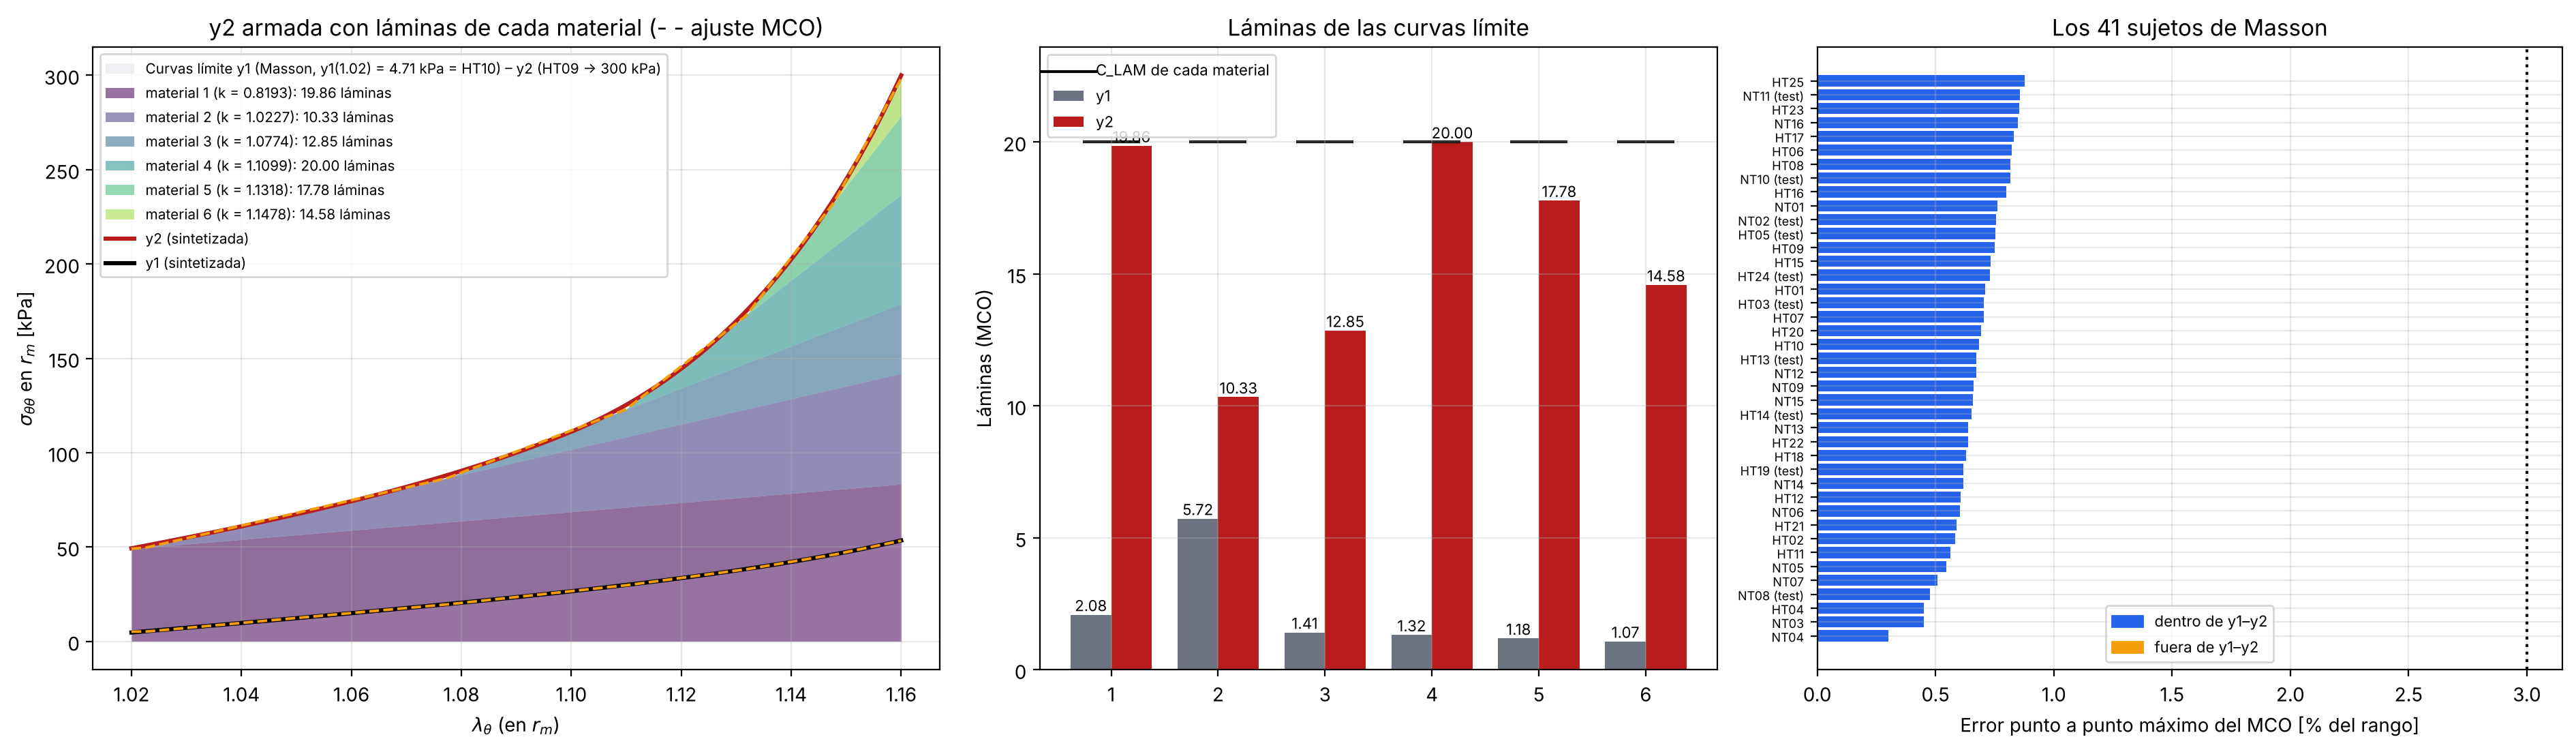

In [6]:
# CELDA 5: y2 ARMADA CON LÁMINAS, LÁMINAS DE LAS CURVAS LÍMITE Y ERROR DE LOS 41 SUJETOS
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

col = plt.cm.viridis(np.linspace(0.0, 0.85, len(NUDOS)))
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1.25, 1, 1.1]))
banda(ax[0])
acum = np.cumsum(np.column_stack([np.zeros_like(X), A * C_Y2]), axis=1)
for j in range(len(NUDOS)):
    ax[0].fill_between(X, acum[:, j], acum[:, j + 1], color=col[j], alpha=0.55, lw=0,
                       label=f"material {j+1} (k = {NUDOS[j]:.4f}): {C_Y2[j]:.2f} láminas")
for y, c, cl, n in [(Y2, C_Y2, "#b91c1c", "y2 (sintetizada)"), (Y1, C_Y1, "k", "y1 (sintetizada)")]:
    ax[0].plot(X, y, color=cl, lw=2.2, label=n)
    ax[0].plot(X, A @ c, "--", color="#f59e0b", lw=1.4)
ax[0].set(xlabel=ETQ_X, ylabel=ETQ_Y, title="y2 armada con láminas de cada material (- - ajuste MCO)")
ax[0].legend(fontsize=7.5, loc="upper left")

i = np.arange(1, len(NUDOS) + 1)
for d, c, cl, n in [(-0.19, C_Y1, "#6b7280", "y1"), (0.19, C_Y2, "#b91c1c", "y2")]:
    ax[1].bar(i + d, c, 0.38, color=cl, label=n)
    for ii, v in zip(i, c):
        ax[1].text(ii + d, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
ax[1].scatter(i, C_LAM, marker="_", s=900, color="k", label="C_LAM de cada material")
ax[1].set(xticks=i, ylabel="Láminas (MCO)", ylim=(0, 1.18 * max(C_LAM.max(), C_Y2.max())), title="Láminas de las curvas límite")
ax[1].legend(fontsize=8, loc="upper left")

d = DF_PISO.sort_values("MaxAE_rel_pct")
ax[2].barh(range(len(d)), d.MaxAE_rel_pct, color=np.where(d.en_espacio, "#2563eb", "#f59e0b"))
ax[2].set_yticks(range(len(d)), [f"{n}{' (test)' if t else ''}" for n, t in zip(d.id, d.test)], fontsize=6.5)
ax[2].axvline(ERROR_MAX_PCT, color="k", ls=":")
ax[2].set(xlabel="Error punto a punto máximo del MCO [% del rango]", title="Los 41 sujetos de Masson")
ax[2].legend(handles=[Patch(color="#2563eb", label="dentro de y1–y2"), Patch(color="#f59e0b", label="fuera de y1–y2")], fontsize=8)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"laminas_curvas_limite_{VERSION}.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# CELDA 6: LIBRERÍAS, TENSORFLOW, ENTRADA LOGARÍTMICA, MÉTRICAS, CONTROL DE CLASE Y PREDICCIÓN DE LA RED
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np
import tensorflow as tf
from scipy.optimize import nnls

np.random.seed(SEED)
tf.random.set_seed(SEED)
OFFSET_LOG = float(max(0.0, -min(Y1.min(), POB_Y.min())) + round(0.18 * np.median(POB_Y[:, -1])))   # entrada: log(y + OFFSET_LOG); la
#   constante crece con la escala de las curvas (σ ≈ 5 veces P): con 5 kPa el logaritmo aplastaba el tramo final, donde actúan los últimos materiales


def entrada_log(Y):
    return np.log(np.maximum(np.asarray(Y) + OFFSET_LOG, 1e-6))


def metricas(Y, B):
    """R², RMSE, MaxAE [kPa], NRMSE y MaxAE_rel [% del rango de cada curva]; una curva o una por fila."""
    Y, E = np.atleast_2d(Y), np.atleast_2d(Y) - np.atleast_2d(B)
    rg, rmse, maxae = np.ptp(Y, axis=1), np.sqrt(np.mean(E ** 2, axis=1)), np.abs(E).max(axis=1)
    m = dict(R2=1 - np.sum(E ** 2, axis=1) / np.sum((Y - Y.mean(axis=1, keepdims=True)) ** 2, axis=1),
             RMSE=rmse, MaxAE=maxae, NRMSE=rmse / rg * 100, MaxAE_rel=maxae / rg * 100)
    return {k: (float(v[0]) if len(v) == 1 else v) for k, v in m.items()}


def predecir(Y):
    """Láminas de cada material (diseño, C_LAM) que predice la red para una curva o una por fila."""
    c = sy.inverse_transform(model.predict(sx.transform(entrada_log(np.atleast_2d(Y))), batch_size=1024, verbose=0)) * ESC
    return c[0] if np.ndim(Y) == 1 else c


def panel(ax, s, titulo):
    """Curva de test #s: entrada, óptimo MCO y red (la usan las Celdas 13, 16 y 18)."""
    banda(ax)
    ax.plot(X, B_IN[s], "k-", lw=2, label="Curva de entrada")
    ax.plot(X, B_OPT[s], "b:", lw=1.8, label="Óptimo MCO")
    ax.plot(X, B_RN[s], "r--", lw=1.8, label="Red")
    ax.set_ylim(-0.03 * max(B_IN[s].max(), 1), 1.15 * max(B_IN[s].max(), 1))
    ax.set_title(titulo, fontsize=8.5, fontweight="bold")
    ax.set(xlabel=ETQ_X, ylabel=ETQ_Y)
    ax.grid(alpha=0.4, ls=":")
    ax.legend(fontsize=7, loc="upper left")


_K = np.linspace(NUDO_MIN_CLASE, X_MAX, N_NUDOS_CLASE + 2)[:-1]
_B_CLASE = np.maximum(0.0, X[:, None] - _K)[::3] / (X_MAX - _K)


def distancia_clase(y):
    """Distancia [% del rango] de y a las curvas realizables con capas (combinaciones c ≥ 0 de 40 líneas truncadas)."""
    ys = np.asarray(y)[::3]
    return float(np.sqrt(np.mean((ys - _B_CLASE @ nnls(_B_CLASE, ys)[0]) ** 2)) / np.ptp(y) * 100)


print(f"✅ TensorFlow {tf.__version__} ({'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}) | OFFSET_LOG = {OFFSET_LOG:g} | "
      f"control de clase: distancia ≤ {TOL_CLASE_NRMSE}%")

I0000 00:00:1794098355.485927     192 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794098356.458651     192 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


✅ TensorFlow 2.21.0 (CPU) | OFFSET_LOG = 22 | control de clase: distancia ≤ 2.0%


In [8]:
# CELDA 7: DATASET SINTÉTICO — V40: etiqueta = láminas ENTERAS del redondeo minimax (MILP, HiGHS) de la curva que ve la red
#   (en la escala del diseño, C_LAM = 20, y pasadas a láminas de la red: z / ESC). Antes (V39): láminas reales del MCO.
#   0 pura: un material, láminas log-uniformes en [0,1; C_GEN_MAX_j]   1 combinada: 2–N materiales, U(0, C_GEN_MAX_j)
#   + las familias fisiológicas de la Celda 2
import numpy as np
import pandas as pd

C_MIN_PURA, RUIDO_PURAS = 0.10, 0.005
rng_b = np.random.default_rng(2028)
nb = len(NUDOS)
c0 = np.zeros((N_FAM[0], nb))
j0 = rng_b.permutation(np.arange(N_FAM[0]) % nb)
c0[np.arange(N_FAM[0]), j0] = np.exp(rng_b.uniform(np.log(C_MIN_PURA), np.log(C_GEN_MAX[j0])))
c1 = np.zeros((N_FAM[1], nb))
for i in range(N_FAM[1]):
    act = rng_b.choice(nb, size=rng_b.integers(2, nb + 1), replace=False)
    c1[i, act] = rng_b.uniform(0.0, 1.0, size=len(act)) * C_GEN_MAX[act]
c1 *= np.minimum(1.0, Y_TECHO / np.maximum((c1 @ A_RED.T).max(axis=1, keepdims=True), 1e-9))
for f, c in ((0, c0), (1, c1)):
    LIMPIAS[f] = c @ A_RED.T
    RUIDOSAS[f] = ruido(LIMPIAS[f], RUIDO_PURAS, rng_b)

Y_limpio, Y_raw = (np.vstack([D[f] for f in sorted(FAMILIAS)]) for D in (LIMPIAS, RUIDOSAS))
familia = np.concatenate([np.full(N_FAM[f], f, np.int8) for f in sorted(FAMILIAS)])
C_RED_MCO = mco(Y_raw, A_RED)                                       # láminas reales del MCO (solo para comparar)
import os, sys, time, contextlib
from scipy.optimize import milp, LinearConstraint, Bounds


@contextlib.contextmanager
def _sin_texto():
    sys.stdout.flush()
    fd, nul = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    os.dup2(nul, 1)
    try:
        yield
    finally:
        os.dup2(fd, 1); os.close(fd); os.close(nul)


def minimax_entero(y, B, z0=None):
    """Redondeo minimax por MILP (HiGHS), 500 puntos de λ, sin acotar la búsqueda (óptimo global)."""
    Bs, ys = B[::2], y[::2]
    m, n = Bs.shape
    lo, hi = np.zeros(n + 1), np.r_[np.full(n, Z_MAX), np.inf]   # V55: 0 ≤ z ≤ Z_MAX
    with _sin_texto():
        r = milp(np.r_[np.zeros(n), 1.0], integrality=np.r_[np.ones(n), 0], bounds=Bounds(lo, hi),
                 constraints=LinearConstraint(np.vstack([np.c_[Bs, -np.ones(m)], np.c_[-Bs, -np.ones(m)]]), -np.inf, np.r_[ys, -ys]),
                 options=dict(time_limit=30))
    if r.x is None:                                                 # HiGHS no llegó a una solución en 30 s:
        z0 = np.zeros(n) if z0 is None else np.maximum(np.round(z0), 0)  # se reintenta en una caja ±6 alrededor del MCO
        lo[:n], hi[:n] = np.maximum(z0 - 6, 0), np.minimum(z0 + 6, Z_MAX)
        with _sin_texto():
            r = milp(np.r_[np.zeros(n), 1.0], integrality=np.r_[np.ones(n), 0], bounds=Bounds(lo, hi),
                     constraints=LinearConstraint(np.vstack([np.c_[Bs, -np.ones(m)], np.c_[-Bs, -np.ones(m)]]), -np.inf, np.r_[ys, -ys]),
                     options=dict(time_limit=120))
        FALLOS_MILP.append(1)
        if r.x is None:
            return np.clip(z0, 0, Z_MAX)
    return np.round(r.x[:n])


FALLOS_MILP = []


if os.path.exists(ARCHIVO_ETIQUETAS_ENTERAS):
    Z_ENT = np.load(ARCHIVO_ETIQUETAS_ENTERAS)["Z"]
    print(f"📦 Etiquetas enteras cargadas de '{ARCHIVO_ETIQUETAS_ENTERAS}'")
else:
    _parcial = ARCHIVO_ETIQUETAS_ENTERAS.replace(".npz", "_parcial.npz")
    Z_ENT, _i0 = np.zeros_like(C_RED_MCO), 0
    if os.path.exists(_parcial):                                    # si se cortó, sigue desde donde quedó
        _p = np.load(_parcial)
        _i0 = int(_p["n"]); Z_ENT[:_i0] = _p["Z"][:_i0]
    _t0, _C20 = time.time(), C_RED_MCO * ESC
    print(f"⏳ Redondeo minimax de {N_SAMPLES} curvas (se guarda cada 2000; ≈ 60 min)...", flush=True)
    for i in range(_i0, N_SAMPLES):
        Z_ENT[i] = minimax_entero(Y_raw[i], A, _C20[i])
        if (i + 1) % 2000 == 0:
            np.savez(_parcial, Z=Z_ENT, n=i + 1)
            print(f"   {i + 1}/{N_SAMPLES} | {(time.time() - _t0) / 60:.1f} min", flush=True)
    np.savez_compressed(ARCHIVO_ETIQUETAS_ENTERAS, Z=Z_ENT, nudos=NUDOS)
    if os.path.exists(_parcial):
        os.remove(_parcial)
    print(f"   Curvas que necesitaron reintento en caja ±6: {len(FALLOS_MILP)}")
C_RED = Z_ENT / ESC                                                 # etiquetas: láminas enteras (escala C_LAM) en láminas de la red
_e_ent = err_pct(Y_raw, Z_ENT @ A.T)[0]
print(f"Etiquetas enteras: error del redondeo minimax contra la curva que ve la red, mediana {np.median(_e_ent):.2f} %, "
      f"p95 {np.percentile(_e_ent, 95):.2f} % | |entero − MCO| medio {np.abs(Z_ENT - C_RED_MCO * ESC).mean():.2f} láminas")
MASCARA = np.zeros_like(C_RED, dtype=np.float32)                    # crosstalk: materiales que el generador dejó en 0
MASCARA[:N_FAM[0] + N_FAM[1]] = np.vstack([c0, c1]) == 0
X_log = entrada_log(Y_raw)

_C0 = mco(Y_limpio, A)
_eM = err_pct(Y_limpio, _C0 @ A.T)[0]
print(f"✅ Dataset: {N_SAMPLES} curvas | etiquetas = láminas ENTERAS (minimax, MILP, HiGHS)")
print(pd.DataFrame({FAMILIAS[f]: {"curvas": N_FAM[f], "puntos fuera de y1–y2 %": 100 * np.mean((Y_raw[m] < Y1) | (Y_raw[m] > Y2)),
                                  "aceptación %": 100 * ACEPTACION.get(f, 1.0), f"MCO cumple ≤{ERROR_MAX_PCT:g}% %": 100 * np.mean(_eM[m] <= ERROR_MAX_PCT),
                                  "error MCO máx. %": _eM[m].max(), "fabricables %": 100 * np.mean((C_RED[m] >= -1e-9).all(1))}
                    for f in FAMILIAS for m in [familia == f]}).T.round(2).to_string())
_esp = np.isin(familia, (2, 3, 5))
print(f"Espacio de trabajo ({_esp.sum()} curvas de Masson dentro de y1–y2): máximo de láminas por material "
      f"{_C0[_esp].max(0).round(2)} (C_LAM = {C_LAM})")

📦 Etiquetas enteras cargadas de 'etiquetas_enteras_v56_6.npz'


Etiquetas enteras: error del redondeo minimax contra la curva que ve la red, mediana 3.07 %, p95 44.76 % | |entero − MCO| medio 0.80 láminas


✅ Dataset: 50000 curvas | etiquetas = láminas ENTERAS (minimax, MILP, HiGHS)


                        curvas  puntos fuera de y1–y2 %  aceptación %  MCO cumple ≤3% %  error MCO máx. %  fabricables %
pura                   10000.0                    93.22        100.00             100.0              0.00          100.0
combinada              10000.0                    29.73        100.00             100.0              0.00          100.0
constitutiva           10000.0                     0.01         97.92             100.0              0.90          100.0
constitutiva_amplia     7500.0                     0.03         88.77             100.0              0.98          100.0
exponencial             5000.0                     3.64         99.74             100.0              1.53          100.0
constitutiva_uniforme   5000.0                     0.00         98.33             100.0              1.10          100.0
pacientes               2500.0                     1.03        100.00             100.0              0.88          100.0
Espacio de trabajo (22500 curvas

In [9]:
# CELDA 8: PARTICIÓN TRAIN / VAL / TEST (estratificada por familia) Y NORMALIZACIÓN
# Con ENTRENAR = False se usan los escaladores guardados con la red; deben coincidir con los de este dataset.
import pickle
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# V56: LA RED SE ENTRENA SOLO DENTRO DE LO QUE PUEDE REPRODUCIR — curvas (sin ruido) dentro de la banda y1–y2 de Masson.
#   Fuera de la banda quedan casi todas las "puras" (un solo material) y la mitad de las "combinadas"; las fisiológicas quedan todas
#   salvo algunas exponenciales. Las etiquetas (minimax, tope Z_MAX) se calcularon para las 50 000 y aquí se filtran.
EN_BANDA = dentro_espacio(Y_limpio)
Y_raw, Y_limpio, familia, Z_ENT, C_RED, C_RED_MCO, MASCARA, X_log = (a[EN_BANDA] for a in
                                                                    (Y_raw, Y_limpio, familia, Z_ENT, C_RED, C_RED_MCO, MASCARA, X_log))
N_GENERADAS, N_SAMPLES = len(EN_BANDA), int(EN_BANDA.sum())
print(f"✅ Dentro de y1–y2: {N_SAMPLES} de {N_GENERADAS} curvas | " +
      ", ".join(f"{FAMILIAS[f]} {int((familia == f).sum())}" for f in FAMILIAS))
idx_trval, idx_test = train_test_split(np.arange(N_SAMPLES), test_size=0.20, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.125, random_state=SEED, stratify=familia[idx_trval])
sx, sy = StandardScaler().fit(X_log[idx_train]), StandardScaler().fit(C_RED[idx_train])
if not ENTRENAR:
    with open(ARCHIVO_SCALERS, "rb") as f:
        meta = pickle.load(f)
    dif = max(np.abs(meta["scaler_x"].mean_ - sx.mean_).max(), np.abs(meta["scaler_y"].mean_ - sy.mean_).max())
    sx, sy = meta["scaler_x"], meta["scaler_y"]
    assert meta["offset_log"] == OFFSET_LOG, "OFFSET_LOG distinto del de la red guardada"
    assert np.allclose(meta["nudos"], NUDOS), f"la red se entrenó con los nudos {np.round(meta['nudos'], 4).tolist()}"
    assert "bases" not in meta or np.allclose(meta["bases"], A_RED, rtol=1e-6, atol=1e-9), \
        "la red se entrenó con otras bases (otros ensayos): borrá sus archivos o poné ENTRENAR = True"
    print(f"📦 Escaladores de '{ARCHIVO_SCALERS}' | diferencia con este dataset: {dif:.1e} (≈ 0 ⇒ mismo dataset de entrenamiento)")
X_train, X_val, X_test = (sx.transform(X_log[i]) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(C_RED[i]) for i in (idx_train, idx_val, idx_test))
m_train, m_val = MASCARA[idx_train], MASCARA[idx_val]
print(f"✅ Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)} | sy.mean_ {sy.mean_.round(4)} | "
      f"sy.scale_ {sy.scale_.round(4)} | crosstalk penalizado en {MASCARA.mean():.1%} de los coeficientes")

✅ Dentro de y1–y2: 34503 de 50000 curvas | pura 144, combinada 4766, constitutiva 10000, constitutiva_amplia 7500, exponencial 4593, constitutiva_uniforme 5000, pacientes 2500


✅ Train 24151 | Val 3451 | Test 6901 | sy.mean_ [4.6353 3.7505 3.3003 3.2353 3.1604 3.0698] | sy.scale_ [1.9109 1.8474 2.2814 2.2603 2.1956 2.2042] | crosstalk penalizado en 3.6% de los coeficientes


In [10]:
# CELDA 9: LÁMINAS ENTERAS — minimax (MILP, HiGHS): la referencia contra la que se comparan las redes (de la Celda 24 de V40)
#   «Redondeo minimax por programación lineal entera mixta (MILP, HiGHS)»: enteros z ≥ 0 de menor error punto a punto máximo,
#       min t  s.a.  −t ≤ y(λ_i) − Σ_j z_j·A_j(λ_i) ≤ t,  z_j entero ≥ 0   (HiGHS: ramificación y acotamiento con planos de corte).
#       Usa solo la curva y las bases (ni el MCO ni la red).
#   «Redondeo por mínimos cuadrados enteros (Schnorr–Euchner)»: enteros de menor E_rms contra la arteria. Como c_MCO es la proyección
#       de y sobre las bases, ||y − A·z||² = ||y − A·c_MCO||² + ||A·(z − c_MCO)||² (Pitágoras): se busca el entero más cercano a c_MCO
#       en la métrica AᵀA, por enumeración de Schnorr–Euchner sobre la factorización de Cholesky (búsqueda exacta).
#   «Redondeo simple»: cada lámina de la red al entero más cercano (referencia: no se recomienda).
import os
import sys
import time
import contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import milp, LinearConstraint, Bounds

N_MUESTRA_ESPACIO = 2000                 # curvas del espacio de trabajo que se redondean (las 22 500 tardan ≈ 20 min)


@contextlib.contextmanager
def _silencio():
    sys.stdout.flush()
    fd, nul = os.dup(1), os.open(os.devnull, os.O_WRONLY)
    os.dup2(nul, 1)
    try:
        yield
    finally:
        os.dup2(fd, 1); os.close(fd); os.close(nul)


def redondeo_minimax(y, B=None, z0=None, caja=None):
    """Redondeo minimax por MILP (HiGHS) en 500 puntos de λ. z0 y caja (± láminas alrededor de z0) solo acotan la búsqueda."""
    B = A if B is None else B
    Bs, ys = B[::2], np.asarray(y, float)[::2]
    m, n = Bs.shape
    lo, hi = np.zeros(n + 1), np.r_[np.full(n, Z_MAX), np.inf]   # V55: 0 ≤ z ≤ Z_MAX
    if z0 is not None and caja is not None:
        lo[:n] = np.maximum(np.round(z0) - caja, 0)
        hi[:n] = np.minimum(np.round(z0) + caja, Z_MAX)
    with _silencio():
        r = milp(np.r_[np.zeros(n), 1.0], integrality=np.r_[np.ones(n), 0], bounds=Bounds(lo, hi),
                 constraints=LinearConstraint(np.vstack([np.c_[Bs, -np.ones(m)], np.c_[-Bs, -np.ones(m)]]), -np.inf, np.r_[ys, -ys]),
                 options=dict(time_limit=60))
    if r.x is None:                     # sin solución en 60 s (raro): se usa el de mínimos cuadrados enteros
        return np.clip(redondeo_mce(np.linalg.lstsq(B, np.asarray(y, float), rcond=None)[0], B), 0, Z_MAX)
    return np.round(r.x[:n])


def redondeo_mce(c, B=None):
    """Redondeo por mínimos cuadrados enteros (Schnorr–Euchner): argmin_{z entero ≥ 0} (z − c)ᵀ BᵀB (z − c), con c = c_MCO."""
    B = A if B is None else B
    M = B.T @ B
    R = np.linalg.cholesky(M).T
    z0 = np.maximum(np.round(c), 0)
    mejor = [float((z0 - c) @ M @ (z0 - c)), z0.copy()]
    z = np.zeros(len(c))

    def nivel(k, parcial):
        s = c[k] - (R[k, k + 1:] @ (z[k + 1:] - c[k + 1:])) / R[k, k]
        radio = np.sqrt(max(mejor[0] - parcial, 0.0)) / abs(R[k, k])
        for v in sorted(range(max(0, int(np.ceil(s - radio))), int(np.floor(s + radio)) + 1), key=lambda v: abs(v - s)):
            z[k] = v
            p = parcial + (R[k, k] * (v - s)) ** 2
            if p < mejor[0]:
                if k == 0:
                    mejor[0], mejor[1] = p, z.copy()
                else:
                    nivel(k - 1, p)
    nivel(len(c) - 1, 0.0)
    return mejor[1]


def errores_curva(y, z, B=None):
    """(E_rms, e_máx) en % del rango de la curva y."""
    B = A if B is None else B
    r = np.asarray(y) - B @ z
    return 100 * np.sqrt(np.mean(r ** 2)) / np.ptp(y), 100 * np.abs(r).max() / np.ptp(y)




In [11]:
# CELDA 10: HERRAMIENTAS DE COMPARACIÓN — e_máx, grupos de curvas, búsqueda de ±1 lámina y tabla contra el minimax
import os, time, json
import numpy as np
import pandas as pd

ESCZ = 20.0                                          # las láminas ya elegidas entran a la red divididas por 20 (C_LAM)
Z = Z_ENT.astype(int)                                # etiquetas: láminas enteras del minimax de cada curva sintética
K = Z_MAX + 1                                        # clases por material: 0, 1, …, Z_MAX láminas (tope de fabricación)
assert Z.max() <= Z_MAX, 'etiquetas por encima del tope'
_idx_esp = np.random.default_rng(SEED + 1).choice(len(W_ESP), min(2000, len(W_ESP)), replace=False)
GRUPOS = {"41 sujetos": (POB_Y, ERROR_MAX_PCT), "2000 curvas": (W_ESP[_idx_esp], 4.0)}   # metas: 3 % (sujetos) y 4 % (espacio)


def emax(Y, Zs):
    """Error punto a punto máximo [% del rango de cada curva] de las láminas Zs (una fila por curva)."""
    R = np.asarray(Y) - np.asarray(Zs) @ A.T
    return 100 * np.abs(R).max(1) / np.ptp(Y, axis=1)


def mejorar_vecinos(Y, Z0, paso=1):
    """Búsqueda de ±1 lámina: prueba z0 + {−1, 0, +1}^N (0 ≤ z ≤ Z_MAX; 3^N combinaciones) y se queda con la de menor e_máx."""
    n = A.shape[1]
    D = np.array(np.meshgrid(*[np.arange(-paso, paso + 1)] * n, indexing="ij")).reshape(n, -1).T
    out = np.zeros_like(Z0, dtype=float)
    for i, (y, z0) in enumerate(zip(Y, Z0)):
        C = np.clip(z0[None, :] + D, 0, Z_MAX)
        out[i] = C[np.abs(y[None, :] - C @ A.T).max(1).argmin()]
    return out


MINIMAX, MS_MINIMAX = {}, {}                         # minimax de cada grupo (se calcula una vez y se guarda) y su tiempo
for _nom, (_Y, _m) in GRUPOS.items():
    _f = f"minimax_{_nom.replace(' ', '_')}_{VERSION}.npz"
    if os.path.exists(_f):
        _d = np.load(_f); MINIMAX[_nom], MS_MINIMAX[_nom] = _d["Z"], float(_d["ms"])
    else:
        _t = time.time()
        MINIMAX[_nom] = np.array([redondeo_minimax(y) for y in _Y])
        MS_MINIMAX[_nom] = (time.time() - _t) / len(_Y) * 1e3
        np.savez(_f, Z=MINIMAX[_nom], ms=MS_MINIMAX[_nom])
    print(f"Minimax de {_nom}: {MS_MINIMAX[_nom]:.0f} ms por curva")
FILAS = []


def comparar(nombre, fn, mejora=False):
    """Agrega a FILAS el resultado de un método (fn: curvas → láminas enteras) en los dos grupos."""
    for nom, (YY, meta) in GRUPOS.items():
        t1 = time.time(); zr = fn(YY)
        if mejora:
            zr = mejorar_vecinos(YY, zr)
        ms = (time.time() - t1) / len(YY) * 1e3
        zm = MINIMAX[nom]; er, em = emax(YY, zr), emax(YY, zm)
        FILAS.append({"método": nombre, "grupo": nom, "mediana %": np.median(er), "peor %": er.max(),
                      "cumplen": int((er <= meta).sum()), "de": len(YY), "meta %": meta,
                      "igual al minimax": int((zr == zm).all(1).sum()), "igual o mejor que el minimax": int((er <= em + 1e-9).sum()),
                      "≤ 1 lámina del minimax": int((np.abs(zr - zm) <= 1).all(1).sum()), "ms por curva": ms})


comparar("Minimax (MILP, HiGHS)", lambda YY: MINIMAX["41 sujetos"] if len(YY) == len(POB_Y) else MINIMAX["2000 curvas"])
for _r in FILAS:
    _r["ms por curva"] = MS_MINIMAX[_r["grupo"]]
print(f"✅ {K} clases por material (0…{K - 1} láminas) | grupos: " + ", ".join(f"{k}: {len(v[0])} curvas (meta {v[1]:g} %)" for k, v in GRUPOS.items()))


Minimax de 41 sujetos: 55 ms por curva
Minimax de 2000 curvas: 50 ms por curva
✅ 21 clases por material (0…20 láminas) | grupos: 41 sujetos: 41 curvas (meta 3 %), 2000 curvas: 2000 curvas (meta 4 %)


In [12]:
# CELDA 11: TRONCO COMÚN Y ENTRENAMIENTO (una sola red: la red en cadena de la Celda 12)
import tensorflow as tf


def tronco(x):
    h = x
    for u in (256, 128, 64):
        h = tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5))(h)
        h = tf.keras.layers.LayerNormalization()(h)
    return h


def entrenar(model, entradas_tr, entradas_va, nombre):
    tf.random.set_seed(SEED); np.random.seed(SEED)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=["sparse_categorical_crossentropy"] * N_BASES)
    cb = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=60, restore_best_weights=True),
          tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=20, min_lr=1e-6)]
    t0 = time.time()
    H = model.fit(entradas_tr, [Z[idx_train, j] for j in range(N_BASES)], validation_data=(entradas_va, [Z[idx_val, j] for j in range(N_BASES)]),
                  epochs=800, batch_size=256, callbacks=cb, verbose=0)
    pd.DataFrame(H.history).to_csv(f"historial_entrenamiento_{VERSION}_{nombre}.csv", index=False)
    print(f"   {nombre}: {len(H.history['loss'])} épocas, {(time.time() - t0) / 60:.1f} min | "
          f"pérdida val. {min(H.history['val_loss']):.3f}")


In [13]:
# CELDA 12: RED EN CADENA — elige los materiales de a uno, sabiendo los anteriores
#   La cabeza del material j recibe la salida del tronco (la curva) y las láminas ya elegidas de los materiales 1 … j−1
#   (divididas por 20), pasa por dos capas (128 y 64, ReLU) y elige 0, 1, 2, … láminas (softmax). Así puede compensar:
#   "si en el material 2 me pasé, en el 3 pongo una lámina menos".
#   Entrenamiento: coeficiente contra coeficiente con los enteros del minimax; a cada cabeza se le dan las láminas EXACTAS
#   del minimax para los materiales anteriores ("teacher forcing"). Uso: elige el material 1, después el 2 sabiendo el 1, etc.
#   Red en cadena + ±1: a su respuesta se le aplica la búsqueda de ±1 lámina de la Celda 10.


def red_cadena():
    x = tf.keras.Input(shape=(X_train.shape[1],), name="curva")
    zprev = tf.keras.Input(shape=(N_BASES,), name="previas")
    h = tronco(x)
    salidas = []
    for j in range(N_BASES):
        e = h if j == 0 else tf.keras.layers.Concatenate()([h, tf.keras.layers.Lambda(lambda t, j=j: t[:, :j])(zprev)])
        e = tf.keras.layers.Dense(128, activation="relu")(e)
        e = tf.keras.layers.Dense(64, activation="relu")(e)
        salidas.append(tf.keras.layers.Dense(K, activation="softmax", name=f"m{j + 1}")(e))
    return tf.keras.Model([x, zprev], salidas)


tf.random.set_seed(SEED)
RED_CAD = red_cadena()
if os.path.exists(ARCHIVO_MODELO) and not ENTRENAR:
    RED_CAD.load_weights(ARCHIVO_MODELO); print(f"📦 Red en cadena cargada de '{ARCHIVO_MODELO}'")
else:
    print("⏳ Entrenando la red en cadena (≈ 25 min)...", flush=True)
    entrenar(RED_CAD, [X_train, Z[idx_train] / ESCZ], [X_val, Z[idx_val] / ESCZ], "cadena"); RED_CAD.save_weights(ARCHIVO_MODELO)
    import pickle
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump({"scaler_x": sx, "scaler_y": sy, "offset_log": OFFSET_LOG, "nudos": NUDOS, "bases": A_RED}, f)


def predecir_cadena(Y):
    Xs = sx.transform(entrada_log(np.atleast_2d(Y)))
    zp = np.zeros((len(Xs), N_BASES))
    for j in range(N_BASES):                         # material 1, después el 2 sabiendo el 1, …
        zp[:, j] = RED_CAD.predict([Xs, zp / ESCZ], batch_size=1024, verbose=0)[j].argmax(1)
    return zp


comparar("Red en cadena", predecir_cadena)
comparar("Red en cadena + búsqueda ±1", predecir_cadena, mejora=True)
print(f"Cabezas: {N_BASES} | clases por cabeza: {K} (0 a {Z_MAX} láminas) | parámetros de la red en cadena: {RED_CAD.count_params():,}")


⏳ Entrenando la red en cadena (≈ 25 min)...


   cadena: 479 épocas, 9.3 min | pérdida val. 6.347


Cabezas: 6 | clases por cabeza: 21 (0 a 20 láminas) | parámetros de la red en cadena: 407,614


In [14]:
# CELDA 13: CURVAS DE PRUEBA — cuántas veces cada red da exactamente el entero del minimax (etiqueta de la curva)
_Yte, _Zte = Y_raw[idx_test], Z[idx_test]
TEST = []
for nombre, fn in (("Red en cadena", predecir_cadena),):
    zt = fn(_Yte)
    TEST.append({"método": nombre, "mismo entero que el minimax %": 100 * np.mean((zt == _Zte).all(1)),
                 "≤ 1 lámina en cada material %": 100 * np.mean((np.abs(zt - _Zte) <= 1).all(1)),
                 **{f"acierto material {j + 1} %": 100 * np.mean(zt[:, j] == _Zte[:, j]) for j in range(N_BASES)}})
TEST = pd.DataFrame(TEST).set_index("método")
TEST.round(1).to_csv(f"test_enteros_{VERSION}.csv")
print(f"Curvas de prueba ({len(idx_test)}): acierto contra las láminas enteras del minimax")
print(TEST.round(1).T.to_string())


Curvas de prueba (6901): acierto contra las láminas enteras del minimax
método                         Red en cadena
mismo entero que el minimax %            6.1
≤ 1 lámina en cada material %           31.9
acierto material 1 %                    62.5
acierto material 2 %                    47.6
acierto material 3 %                    29.5
acierto material 4 %                    25.2
acierto material 5 %                    30.6
acierto material 6 %                    32.5


In [15]:
# CELDA 14: TABLA FINAL — minimax, red por separado, red en cadena, y ambas con la búsqueda de ±1
RES = pd.DataFrame(FILAS)
RES.round(3).to_csv(f"comparacion_enteros_{VERSION}.csv", index=False)
for g, (_, meta) in GRUPOS.items():
    t = RES[RES["grupo"] == g].set_index("método")
    print(f"\n{g} (meta {meta:g} %): e_máx [% del rango] y coincidencia con el minimax")
    print(t[["mediana %", "peor %", "cumplen", "de", "igual al minimax", "igual o mejor que el minimax", "ms por curva"]]
          .to_string(float_format=lambda v: f"{v:.2f}"))



41 sujetos (meta 3 %): e_máx [% del rango] y coincidencia con el minimax
                             mediana %  peor %  cumplen  de  igual al minimax  igual o mejor que el minimax  ms por curva
método                                                                                                                   
Minimax (MILP, HiGHS)             1.02    2.34       41  41                41                            41         54.89
Red en cadena                     1.47    2.90       41  41                 6                            12         12.59
Red en cadena + búsqueda ±1       1.11    2.34       41  41                13                            24         10.08

2000 curvas (meta 4 %): e_máx [% del rango] y coincidencia con el minimax
                             mediana %  peor %  cumplen    de  igual al minimax  igual o mejor que el minimax  ms por curva
método                                                                                                               

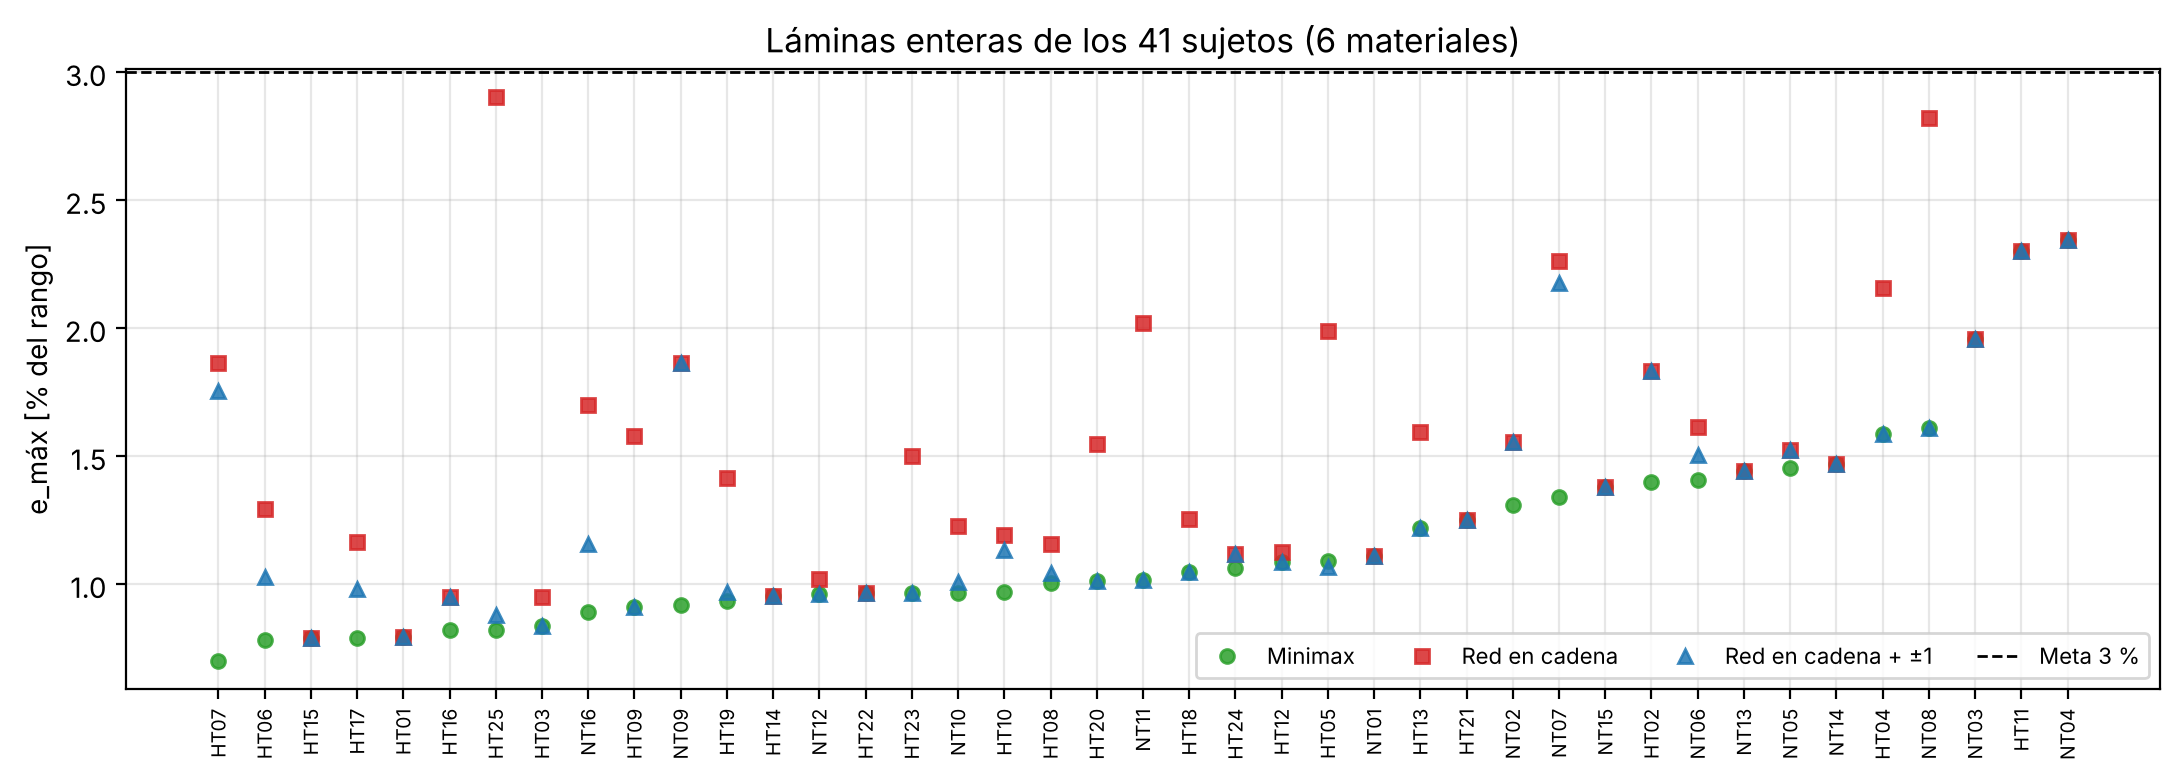

In [16]:
# CELDA 15: FIGURA — e_máx de los 41 sujetos: minimax, red en cadena y red en cadena + ±1
import matplotlib.pyplot as plt
_Y = POB_Y
_z = {"Minimax": MINIMAX["41 sujetos"], "Red en cadena": predecir_cadena(_Y)}
_z["Red en cadena + ±1"] = mejorar_vecinos(_Y, _z["Red en cadena"])
_o = np.argsort(emax(_Y, _z["Minimax"]))
fig, ax = plt.subplots(figsize=(11, 4))
for (nom, z), (c, mk) in zip(_z.items(), (("tab:green", "o"), ("tab:red", "s"), ("tab:blue", "^"))):
    ax.plot(np.arange(len(_Y)), emax(_Y, z)[_o], mk, color=c, ms=5, label=nom, alpha=0.85)
ax.axhline(ERROR_MAX_PCT, color="k", ls="--", lw=1, label=f"Meta {ERROR_MAX_PCT:g} %")
ax.set_xticks(np.arange(len(_Y))); ax.set_xticklabels(POB["id"].to_numpy()[_o], rotation=90, fontsize=7)
ax.set_ylabel("e_máx [% del rango]"); ax.set_title(f"Láminas enteras de los 41 sujetos ({N_BASES} materiales)")
ax.legend(ncol=4, fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"enteros_41_sujetos_{VERSION}.png", dpi=200, bbox_inches="tight"); plt.show()
